# Results analysis

This notebook reads every `evaluation/summary.json` that `experiments.evaluate` wrote under
`experiments/results/`, puts them in one table with a row per run, and compares the runs:
chunking methods against each other on the baseline pipeline, how each metric moves with the
chunk size, how the span metrics agree with RAGAS, what each run cost, and, question by
question, where two runs differ.

Every chart is followed by the table it was drawn from, which gives the exact figures.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullLocator

# The notebook runs from experiments/ (or from the repository root); the root must be on
# the path for `rag` and `experiments` to be importable.
ROOT = Path.cwd() if (Path.cwd() / "rag").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from experiments.common import CHUNKS, RESULTS, load_chunks, load_items, read_json, read_jsonl
from experiments.compare import cost
from rag.evaluation import relevant_chunks, score

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:.3f}".format)

## Settings

`METRIC` picks each method's best parameters and is the one the charts plot. `JUDGE` is the
RAGAS entry read from the summaries, named `<judge model>-k=<k>` as `experiments.evaluate`
writes it. `BASELINE` is the pipeline every stage but chunking is fixed at in the chunking
comparison (see the README, "Comparison of methods, one stage at a time").

In [2]:
METRIC = "evidence_recall@5"
JUDGE = "openweight-large-k=5"
BASELINE = {"augmentation": "none", "embedding": "bge-m3", "retrieval": "dense-top_k=50",
            "reranking": "none"}
REFERENCE = "txt, fixed_token"

## Chart style

Each chunking method keeps one color and one marker in every chart, whatever else is shown,
so a method is recognised at a glance and never by color alone. The colors are the first
seven slots of a palette checked for color-vision deficiencies; methods not listed fall back
to gray.

In [3]:
COLORS = {"txt, fixed_token": "#2a78d6", "txt, sentence": "#eb6834", "md, markdown": "#1baf7a",
          "html, html": "#eda100", "txt, semantic": "#e87ba4", "txt, clustered": "#008300",
          "txt, lumberchunker": "#4a3aa7"}
MARKERS = {"txt, fixed_token": "o", "txt, sentence": "s", "md, markdown": "^", "html, html": "D",
           "txt, semantic": "v", "txt, clustered": "P", "txt, lumberchunker": "X"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})


def style(method):
    """The color and marker a method is drawn with."""
    return {"color": COLORS.get(method, MUTED), "marker": MARKERS.get(method, "o")}


def method_legend(fig, methods, extra=()):
    """One legend above the panels: a handle per method, then any `extra` handles."""
    handles = [Line2D([], [], label=method, **style(method)) for method in methods]
    fig.legend(handles=[*handles, *extra], loc="upper center", ncol=min(len(handles) + len(extra), 5),
               bbox_to_anchor=(0.5, 1.0))


def panels(count, columns=4, width=3.4, height=2.6):
    """A grid of `count` panels, the unused ones hidden."""
    rows = -(-count // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(width * columns, height * rows + 0.6),
                             squeeze=False)
    for ax in axes.flat[count:]:
        ax.set_visible(False)
    return fig, list(axes.flat[:count])

## Dataset sizes

How large each dataset is: its documents, its questions (split by whether they carry evidence
spans, which the span metrics need), the corpus in tokens, and how long its documents are.
Tokens are tiktoken `cl100k_base`, the encoding the chunking budgets are counted in, of the
plain-text rendering. Corpus size is what ingestion costs scale with, and document length is
what decides how many chunks a question's answer competes with inside its own document.

c:\Temp\ipykernel_34152\2063876129.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[3].boxplot([lengths[dataset] for dataset in sizes.index], vert=False, positions=list(y),


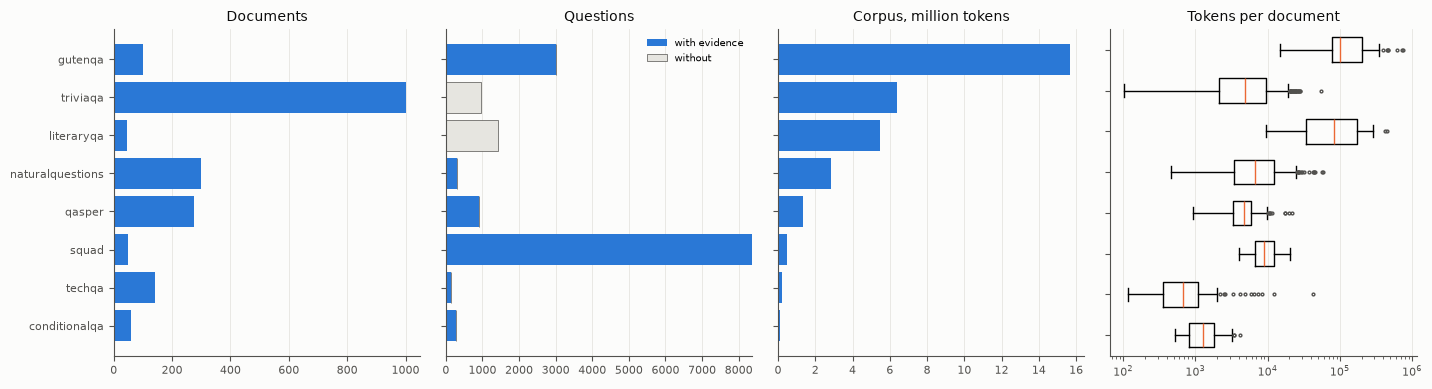

,documents,questions,with_evidence,without_evidence,characters,tokens,median_doc_tokens,max_doc_tokens,renderings,tokens_per_char
dataset,,,,,,,,,,
conditionalqa,59,271,271,0,418531,88766,1275,4186,"md, html",0.212
techqa,141,151,151,0,777456,191768,683,41995,,0.247
squad,48,8371,8371,0,2230556,465692,8890,20364,,0.209
qasper,276,910,892,18,6600291,1360478,4719,21500,md,0.206
naturalquestions,300,314,314,0,11114702,2820619,6636,58532,"md, html",0.254
literaryqa,47,1417,0,1417,23217802,5459208,82434,454277,"md, html",0.235
triviaqa,1000,947,0,947,29003728,6391304,4798,55170,,0.220
gutenqa,100,3000,3000,0,67058043,15662099,101680,741330,,0.234


In [4]:
import tiktoken

from experiments.common import DATASETS, read_documents

encoding = tiktoken.get_encoding("cl100k_base")
rows, lengths = [], {}
for directory in sorted(path.parent for path in DATASETS.glob("*/data/items.jsonl")):
    dataset = directory.parent.name
    texts = [text for _, text in read_documents(dataset)]
    tokens = [len(ids) for ids in encoding.encode_ordinary_batch(texts)]
    items = read_jsonl(directory / "items.jsonl")
    with_evidence = sum(1 for item in items if item["evidences"])
    lengths[dataset] = tokens
    rows.append({"dataset": dataset, "documents": len(texts), "questions": len(items),
                 "with_evidence": with_evidence, "without_evidence": len(items) - with_evidence,
                 "characters": sum(map(len, texts)), "tokens": sum(tokens),
                 "median_doc_tokens": int(pd.Series(tokens).median()), "max_doc_tokens": max(tokens),
                 "renderings": ", ".join(name for name in ("md", "html")
                                         if (directory / f"documents_{name}").is_dir())})
sizes = pd.DataFrame(rows).set_index("dataset").sort_values("tokens")
sizes["tokens_per_char"] = sizes["tokens"] / sizes["characters"]

fig, axes = panels(4, columns=4, width=3.6, height=0.32 * len(sizes) + 0.8)
y = range(len(sizes))
axes[0].barh(y, sizes["documents"], color=COLORS["txt, fixed_token"])
axes[0].set_title("Documents")
axes[1].barh(y, sizes["with_evidence"], color=COLORS["txt, fixed_token"], label="with evidence")
axes[1].barh(y, sizes["without_evidence"], left=sizes["with_evidence"], color=GRID,
             edgecolor=MUTED, linewidth=0.5, label="without")
axes[1].set_title("Questions")
axes[1].legend(loc="upper right", fontsize=7)
axes[2].barh(y, sizes["tokens"] / 1e6, color=COLORS["txt, fixed_token"])
axes[2].set_title("Corpus, million tokens")
axes[3].boxplot([lengths[dataset] for dataset in sizes.index], vert=False, positions=list(y),
                widths=0.6, flierprops={"markersize": 2, "markeredgecolor": MUTED},
                medianprops={"color": COLORS["txt, sentence"]})
axes[3].set_xscale("log")
axes[3].set_title("Tokens per document")
for ax in axes:
    ax.set_yticks(list(y), sizes.index if ax is axes[0] else [])
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
sizes

## Every run in one table

One row per retrieval or reranking run that has been evaluated. The metrics are those of the
`evidence` group of questions, or of `no_evidence` for a dataset without evidence spans
(LiteraryQA), which has only `doc_hit`. The RAGAS columns are filled where `JUDGE` judged the
run. `summaries` keeps the raw summaries, for `experiments.compare.cost`.

In [5]:
def flatten(summary):
    """One run's summary as a flat row."""
    chunking = summary["chunking"]
    params = chunking["chunking"]["params"]
    group = "evidence" if "evidence" in summary["metrics"] else "no_evidence"
    queried = summary.get("cost") or {}
    row = {
        "dataset": summary["dataset"],
        "method": f"{chunking['rendering']}, {chunking['chunking']['method']}",
        "max_tokens": params.get("max_tokens"),
        "overlap": params.get("overlap"),
        "params": ", ".join(f"{key}={value}" for key, value in params.items()),
        "augmentation": "+".join(chunking["augmentations"]) or "none",
        "embedding": summary["embedding"]["model"],
        "retrieval": f"{summary['retrieval']['method']}-top_k={summary['retrieval']['top_k']}",
        "reranking": summary["reranking"]["model"] if summary["reranking"] else "none",
        "documents": summary["documents"],
        "chunks": summary["chunks"],
        "chunk_chars": summary["mean_chunk_chars"],
        "group": group,
        "items": summary["items"][group],
        **summary["metrics"].get(group, {}),
        "query_s": (queried["retrieval_seconds"] + queried.get("rerank_seconds", 0)
                    if "retrieval_seconds" in queried else None),
        "run": summary["run"],
    }
    judged = summary.get("ragas", {}).get(JUDGE)
    if judged:
        k = judged["k"]
        row.update({f"context_precision@{k}": judged[f"context_precision@{k}"],
                    f"context_recall@{k}": judged[f"context_recall@{k}"],
                    "judged": judged["items"] - judged["failed"]})
    return row


summaries = {}
for path in sorted(RESULTS.glob("**/evaluation/summary.json")):
    summary = read_json(path)
    summaries[summary["run"]] = summary
runs = pd.DataFrame([flatten(summary) for summary in summaries.values()]).set_index("run")
print(f"{len(runs)} evaluated runs over {runs['dataset'].nunique()} datasets")
runs.head()

114 evaluated runs over 7 datasets


,dataset,method,max_tokens,overlap,params,augmentation,embedding,retrieval,reranking,documents,chunks,chunk_chars,group,items,doc_hit@1,doc_hit@3,doc_hit@5,doc_hit@10,mrr@10,hit@1,ndcg@1,evidence_recall@1,hit@3,ndcg@3,evidence_recall@3,hit@5,ndcg@5,evidence_recall@5,hit@10,ndcg@10,evidence_recall@10,query_s,context_precision@5,context_recall@5,judged
run,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
conditionalqa/html/html-max_tokens=1024/none/bge-m3/dense-top_k=50,conditionalqa,"html, html",1024.000,NaN,"max_tokens=1024, headings=['h1', 'h2', 'h3', 'h4', 'h5', 'h6']",none,bge-m3,dense-top_k=50,none,59,1208,391.063,evidence,271,0.959,0.989,0.989,0.996,0.744,0.613,0.613,0.419,0.871,0.653,0.690,0.915,0.686,0.786,0.959,0.731,0.892,0.031,0.747,0.870,100.000
conditionalqa/html/html-max_tokens=256/none/bge-m3/dense-top_k=50,conditionalqa,"html, html",256.000,NaN,"max_tokens=256, headings=['h1', 'h2', 'h3', 'h4', 'h5', 'h6']",none,bge-m3,dense-top_k=50,none,59,1233,383.114,evidence,271,0.963,0.989,0.989,0.996,0.746,0.616,0.616,0.421,0.871,0.653,0.690,0.915,0.686,0.783,0.956,0.729,0.885,0.025,0.750,0.860,100.000
conditionalqa/html/html-max_tokens=512/none/bge-m3/dense-top_k=50,conditionalqa,"html, html",512.000,NaN,"max_tokens=512, headings=['h1', 'h2', 'h3', 'h4', 'h5', 'h6']",none,bge-m3,dense-top_k=50,none,59,1208,391.063,evidence,271,0.959,0.989,0.989,0.996,0.744,0.613,0.613,0.419,0.871,0.653,0.690,0.915,0.686,0.786,0.956,0.729,0.887,0.026,0.751,0.828,99.000
conditionalqa/md/markdown-max_tokens=1024/none/bge-m3/dense-top_k=50,conditionalqa,"md, markdown",1024.000,NaN,max_tokens=1024,none,bge-m3,dense-top_k=50,none,59,1149,369.220,evidence,271,0.956,0.985,0.993,0.996,0.770,0.646,0.646,0.447,0.878,0.673,0.703,0.919,0.709,0.802,0.967,0.750,0.897,0.019,0.791,0.859,99.000
conditionalqa/md/markdown-max_tokens=256/none/bge-m3/dense-top_k=50,conditionalqa,"md, markdown",256.000,NaN,max_tokens=256,none,bge-m3,dense-top_k=50,none,59,1162,365.067,evidence,271,0.952,0.985,0.993,0.996,0.768,0.642,0.642,0.444,0.878,0.674,0.705,0.919,0.709,0.801,0.963,0.748,0.894,0.017,0.788,0.880,100.000


In [6]:
# How many runs each dataset has per chunking method.
runs.groupby(["dataset", "method"]).size().unstack(fill_value=0)

method,"html, html","md, markdown","txt, clustered","txt, fixed_token","txt, lumberchunker","txt, semantic","txt, sentence"
dataset,,,,,,,
conditionalqa,3,3,1,6,1,1,6
gutenqa,0,0,0,6,0,0,6
naturalquestions,3,3,1,6,1,1,6
qasper,0,3,1,6,1,1,6
squad,0,0,1,6,1,1,6
techqa,0,0,1,6,1,1,6
triviaqa,0,0,0,6,0,0,6


## The chunking comparison, on the baseline pipeline

Only runs of the baseline pipeline are kept, so the chunking method and its parameters are the
only things that differ between two rows. Each method is shown at the parameters that scored
best on `METRIC`, per dataset, as `experiments.compare_chunking` does.

In [7]:
baseline = runs[(runs[list(BASELINE)] == pd.Series(BASELINE)).all(axis=1)
                & (runs["group"] == "evidence")]
best = baseline.loc[baseline.groupby(["dataset", "method"])[METRIC].idxmax()]
best[["dataset", "method", "params", "documents", "items", "chunks", "chunk_chars",
      "evidence_recall@5", "hit@5", "context_recall@5", "ndcg@10"]]

,dataset,method,params,documents,items,chunks,chunk_chars,evidence_recall@5,hit@5,context_recall@5,ndcg@10
run,,,,,,,,,,,
conditionalqa/html/html-max_tokens=1024/none/bge-m3/dense-top_k=50,conditionalqa,"html, html","max_tokens=1024, headings=['h1', 'h2', 'h3', 'h4', 'h5', 'h6']",59,271,1208,391.063,0.786,0.915,0.870,0.731
conditionalqa/md/markdown-max_tokens=1024/none/bge-m3/dense-top_k=50,conditionalqa,"md, markdown",max_tokens=1024,59,271,1149,369.220,0.802,0.919,0.859,0.750
conditionalqa/txt/clustered-embedding_model=bge-m3/none/bge-m3/dense-top_k=50,conditionalqa,"txt, clustered","percentile=95, threshold=None, max_tokens=1024, buffer=1",59,271,409,1021.604,0.937,0.974,0.889,0.823
conditionalqa/txt/fixed_token-max_tokens=1024-overlap=0.25/none/bge-m3/dense-top_k=50,conditionalqa,"txt, fixed_token","max_tokens=1024, overlap=0.25",59,271,124,4006.032,0.982,0.985,0.889,0.915
conditionalqa/txt/lumberchunker-llm_model=openweight-large/none/bge-m3/dense-top_k=50,conditionalqa,"txt, lumberchunker",,59,271,717,581.890,0.857,0.930,NaN,0.810
conditionalqa/txt/semantic-embedding_model=bge-m3/none/bge-m3/dense-top_k=50,conditionalqa,"txt, semantic","breakpoint_percentile=95, buffer_size=1",59,271,407,1028.332,0.920,0.959,0.880,0.819
conditionalqa/txt/sentence-max_tokens=1024-overlap=0/none/bge-m3/dense-top_k=50,conditionalqa,"txt, sentence","max_tokens=1024, overlap=0",59,271,116,3607.043,0.979,0.982,0.889,0.911
gutenqa/txt/fixed_token-max_tokens=256-overlap=0.25/none/bge-m3/dense-top_k=50,gutenqa,"txt, fixed_token","max_tokens=256, overlap=0.25",100,300,82468,1084.829,0.637,0.677,0.672,0.526
gutenqa/txt/sentence-max_tokens=512-overlap=0/none/bge-m3/dense-top_k=50,gutenqa,"txt, sentence","max_tokens=512, overlap=0",100,300,37825,1771.224,0.693,0.707,0.681,0.629


In [8]:
# The methods against the datasets, each at its best, with the mean difference to the
# reference method over the datasets both ran on.
overview = best.pivot(index="method", columns="dataset", values="evidence_recall@5")
overview["datasets"] = overview.notna().sum(axis=1)
overview[f"mean difference to {REFERENCE}"] = (
    overview.drop(columns="datasets").sub(overview.loc[REFERENCE]).mean(axis=1)
)
overview.sort_values(f"mean difference to {REFERENCE}", ascending=False)

dataset,conditionalqa,gutenqa,naturalquestions,qasper,squad,techqa,datasets,"mean difference to txt, fixed_token"
method,,,,,,,,
"txt, sentence",0.979,0.693,0.840,0.695,0.885,0.954,6,0.006
"txt, fixed_token",0.982,0.637,0.834,0.722,0.860,0.974,6,0.000
"txt, semantic",0.920,NaN,0.789,0.510,0.827,0.827,5,-0.100
"txt, clustered",0.937,NaN,0.730,0.442,0.825,0.815,5,-0.125
"html, html",0.786,NaN,0.763,NaN,NaN,NaN,2,-0.134
"txt, lumberchunker",0.857,NaN,0.709,0.391,0.893,0.778,5,-0.149
"md, markdown",0.802,NaN,0.763,0.361,NaN,NaN,3,-0.204


### The metric against the chunk size

One panel per dataset, each with its own scale, since the datasets' levels differ widely
(Qasper's evidence recall is around 0.2, SQuAD's around 0.9). A solid line is an overlap of 0,
a dashed one an overlap of 0.25. Methods without a size parameter (the semantic ones,
LumberChunker) have no line here; they appear in the next chart.

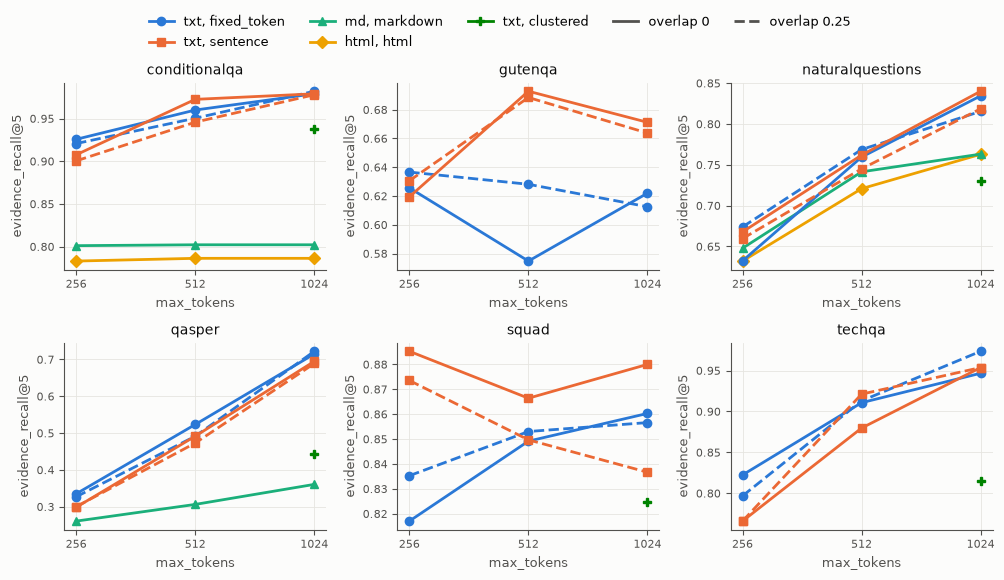

In [9]:
sized = baseline[baseline["max_tokens"].notna()]
datasets = sorted(sized["dataset"].unique())
methods = [method for method in COLORS if method in set(sized["method"])]
fig, axes = panels(len(datasets), columns=3)
for ax, dataset in zip(axes, datasets):
    for (method, overlap), group in sized[sized["dataset"] == dataset].groupby(
            ["method", sized["overlap"].fillna(0)]):
        group = group.sort_values("max_tokens")
        ax.plot(group["max_tokens"], group[METRIC], linestyle="--" if overlap else "-",
                **style(method))
    ax.set_xscale("log", base=2)
    ax.set_xticks([256, 512, 1024], ["256", "512", "1024"])
    ax.minorticks_off()
    ax.set_title(dataset)
    ax.set_xlabel("max_tokens")
    ax.set_ylabel(METRIC)
method_legend(fig, methods, [Line2D([], [], color=MUTED, linestyle="-", label="overlap 0"),
                             Line2D([], [], color=MUTED, linestyle="--", label="overlap 0.25")])
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
# sized.pivot_table(index=["dataset", "method", "overlap"], columns="max_tokens", values=METRIC)

### The metric against the chunk length

Every metric favours large chunks, so a method is better only if it scores higher at the same
length. Each point is one run; the horizontal axis is the mean chunk length in characters, on a
log scale. A method above and to the left of another does better with shorter chunks.

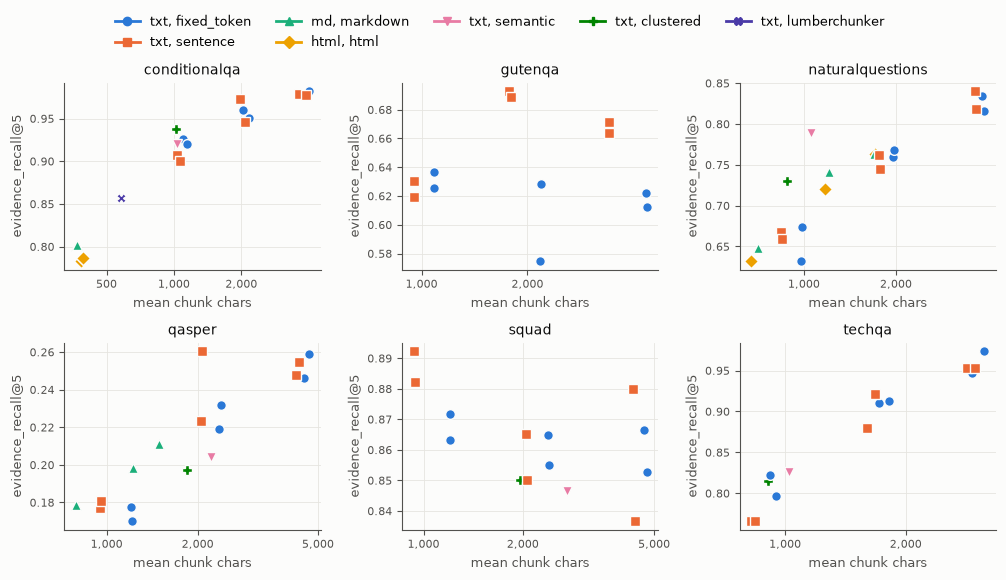

In [11]:
datasets = sorted(baseline["dataset"].unique())
methods = [method for method in COLORS if method in set(baseline["method"])]
methods += sorted(set(baseline["method"]) - set(methods))
fig, axes = panels(len(datasets), columns=3)
for ax, dataset in zip(axes, datasets):
    for method, group in baseline[baseline["dataset"] == dataset].groupby("method"):
        group = group.sort_values("chunk_chars")
        ax.plot(group["chunk_chars"], group[METRIC], linestyle="none", markersize=7,
                markeredgecolor=SURFACE, markeredgewidth=1, **style(method))
    ax.set_xscale("log")
    # Plain labels at 1, 2 and 5 of each decade; matplotlib's own run together.
    ax.xaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_title(dataset)
    ax.set_xlabel("mean chunk chars")
    ax.set_ylabel(METRIC)
method_legend(fig, methods)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
# baseline[["dataset", "method", "params", "chunk_chars", METRIC]].sort_values(
#     ["dataset", "chunk_chars"])

### Evidence recall at every cut-off

How much of the evidence each method's best run covers as more chunks are read, k = 1, 3, 5
and 10. A method whose curve starts lower but ends higher ranks the evidence lower but still
finds it.

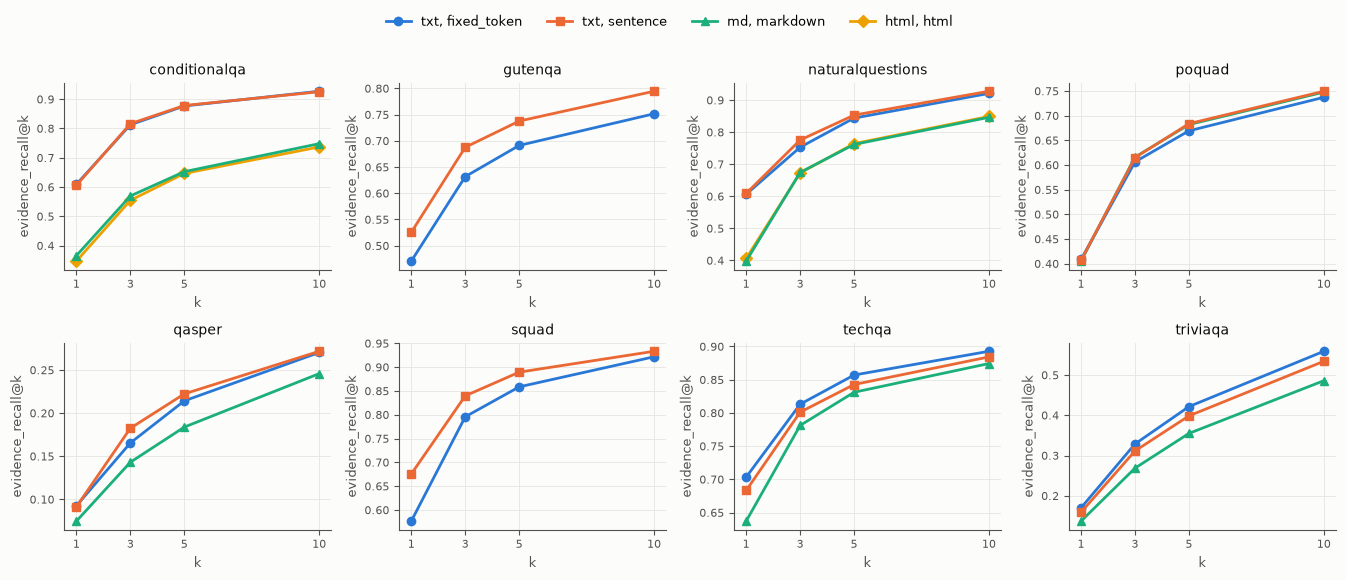

evidence_recall@1  evidence_recall@3  evidence_recall@5  evidence_recall@10
dataset          method                                                                                       
conditionalqa    html, html                    0.347              0.555              0.647               0.737
                 md, markdown                  0.366              0.570              0.653               0.748
                 txt, fixed_token              0.609              0.813              0.877               0.927
                 txt, sentence                 0.606              0.816              0.878               0.925
gutenqa          txt, fixed_token              0.471              0.632              0.691               0.752
                 txt, sentence                 0.526              0.688              0.738               0.795
naturalquestions html, html                    0.406              0.673              0.764               0.849
                 md, markdown                  0.398              0.674              0.762               0.846
                 txt, fixed_token              0.607              0.753              0.844               0.921
                 txt, sentence                 0.609              0.776              0.853               0.928
poquad           md, markdown                  0.405              0.616              0.682               0.748
                 txt, fixed_token              0.409              0.606              0.669               0.737
                 txt, sentence                 0.407              0.615              0.684               0.750
qasper           md, markdown                  0.075              0.143              0.184               0.246
                 txt, fixed_token              0.093              0.165              0.214               0.270
                 txt, sentence                 0.091              0.182              0.222               0.272
squad            txt, fixed_token              0.577              0.796              0.859               0.922
                 txt, sentence                 0.676              0.840              0.889               0.933
techqa           md, markdown                  0.637              0.781              0.831               0.874
                 txt, fixed_token              0.703              0.813              0.857               0.893
                 txt, sentence                 0.683              0.801              0.843               0.884
triviaqa         md, markdown                  0.137              0.269              0.355               0.486
                 txt, fixed_token              0.170              0.329              0.421               0.559
                 txt, sentence                 0.159              0.311              0.398               0.534

In [10]:
ks = [1, 3, 5, 10]
columns = [f"evidence_recall@{k}" for k in ks]
datasets = sorted(best["dataset"].unique())
methods = [method for method in COLORS if method in set(best["method"])]
methods += sorted(set(best["method"]) - set(methods))
fig, axes = panels(len(datasets))
for ax, dataset in zip(axes, datasets):
    for _, row in best[best["dataset"] == dataset].iterrows():
        ax.plot(ks, row[columns].astype(float), **style(row["method"]))
    ax.set_xticks(ks)
    ax.set_title(dataset)
    ax.set_xlabel("k")
    ax.set_ylabel("evidence_recall@k")
method_legend(fig, methods)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
best.set_index(["dataset", "method"])[columns]

## RAGAS against the span metrics

Where `JUDGE` judged a run, its context precision and recall are set against the span metrics.
They disagree where the evidence spans are loose or another chunk says the same thing as the
marked one, and where the judge is lenient (see the README). The table gives each dataset's
Spearman correlation between the two kinds of metric, over its judged runs.

In [ ]:
judged = runs[runs["judged"].notna()] if "judged" in runs else runs.iloc[0:0]
if judged.empty:
    print(f"No run has been judged by {JUDGE} yet.")
else:
    k = int(JUDGE.rsplit("k=", 1)[1])
    pairs = [(f"evidence_recall@{k}", f"context_recall@{k}"),
             (f"ndcg@{k}", f"context_precision@{k}")]
    fig, axes = panels(len(pairs), columns=len(pairs), width=4.2, height=3.6)
    for ax, (span, ragas) in zip(axes, pairs):
        ax.scatter(judged[span], judged[ragas], s=36, color=COLORS[REFERENCE],
                   edgecolors=SURFACE, linewidths=1)
        ax.set_xlabel(span)
        ax.set_ylabel(f"{ragas} ({JUDGE.rsplit('-k=', 1)[0]})")
        ax.set_title(f"{ragas} against {span}")
    fig.tight_layout()
    plt.show()
    correlations = {
        dataset: {f"{span} ~ {ragas}": group[span].corr(group[ragas], method="spearman")
                  for span, ragas in pairs} | {"runs": len(group)}
        for dataset, group in judged.groupby("dataset")}
    display(pd.DataFrame(correlations).T.astype({"runs": int}))

## Cost

What each method's best run cost, from `experiments.compare.cost`: per document of the index,
the seconds to build it (chunking, augmentation and embedding) and the LLM and embedding tokens;
per question, the seconds of retrieval and reranking. A run built before costs were recorded has
gaps.

In [ ]:
costs = pd.DataFrame({run: cost(summaries[run]) for run in best.index}).T
best[["dataset", "method", "params", METRIC]].join(costs).sort_values(["dataset", METRIC],
                                                                       ascending=[True, False])

## Question by question

`per_question(run)` scores one run's rankings question by question, from its `ranking.jsonl`,
the dataset's evidence spans and the index's chunks. Two runs joined on the question show where
one finds the evidence and the other does not; `show_ranking` prints what a run retrieved for
one question, each chunk marked when it overlaps the evidence.

In [ ]:
def per_question(run):
    """The metrics of every question of one run, with the question and its reference answer."""
    summary = summaries[run]
    chunks_by_document = {}
    for chunk in load_chunks(CHUNKS / Path(summary["index"]).parent):
        chunks_by_document.setdefault(chunk.doc_id, []).append(chunk)
    items, _ = load_items(summary["dataset"], summary["chunking"]["rendering"],
                          set(chunks_by_document))
    items = {item["id"]: item for item in items}
    rows = []
    for record in read_jsonl(RESULTS / run / "ranking.jsonl"):
        item = items[record["id"]]
        relevant = relevant_chunks([tuple(span) for span in item["spans"]], chunks_by_document)
        rows.append({"id": item["id"], "question": item["question"], "answer": item["answer"],
                     **score(record["ranking"], item["spans"], item["documents"], relevant)})
    return pd.DataFrame(rows).set_index("id")


def show_ranking(run, question_id, k=5, width=300):
    """Print the first `k` chunks a run retrieved for one question, evidence marked."""
    summary = summaries[run]
    chunks = {(chunk.doc_id, chunk.index): chunk
              for chunk in load_chunks(CHUNKS / Path(summary["index"]).parent)}
    record = next(record for record in read_jsonl(RESULTS / run / "ranking.jsonl")
                  if record["id"] == question_id)
    item = next(item for item in load_items(summary["dataset"], summary["chunking"]["rendering"],
                                            {doc_id for doc_id, _ in chunks})[0]
                if item["id"] == question_id)
    print(f"{item['question']}\nanswer: {item['answer']}\n")
    for rank, (doc_id, start, end, index, value) in enumerate(record["ranking"][:k], start=1):
        overlaps = any(doc_id == span_doc and start < span_end and span_start < end
                       for span_doc, span_start, span_end in item["spans"])
        text = " ".join(chunks[(doc_id, index)].original_text.split())
        print(f"{rank}. {'EVIDENCE' if overlaps else '        '} {doc_id} [{start}:{end}] "
              f"score {value:.3f}\n   {text[:width]}{'...' if len(text) > width else ''}\n")

In [ ]:
# The best sentence run against the best fixed_token run on one dataset: the questions where
# their METRIC differs most, either way.
DATASET = "squad"
first = best[(best["dataset"] == DATASET) & (best["method"] == "txt, sentence")].index[0]
second = best[(best["dataset"] == DATASET) & (best["method"] == REFERENCE)].index[0]
print(f"first:  {first}\nsecond: {second}")
compared = per_question(first)[["question", "answer", METRIC]].join(
    per_question(second)[[METRIC]], rsuffix=" (second)")
compared["difference"] = compared[METRIC] - compared[f"{METRIC} (second)"]
print(f"first better on {(compared['difference'] > 0).sum()} questions, "
      f"second better on {(compared['difference'] < 0).sum()}, "
      f"equal on {(compared['difference'] == 0).sum()}")
compared.sort_values("difference").iloc[list(range(5)) + list(range(-5, 0))]

In [ ]:
# What each run retrieved for the question on which the second run does best by the most.
question = compared["difference"].idxmin()
print("=== first")
show_ranking(first, question)
print("=== second")
show_ranking(second, question)